# ПР №1. Линейные дискретные системы и преобразование Фурье

Студент: Раутио И.А.

Группа: 3388

Вариант №14

## Цель работы

Изучение математического описания линейных дискретных систем и дискретного преобразования Фурье (ДПФ) для периодических последовательностей и последовательностей конечной длины.

## Теоретические сведения

Линейная дискретная система (ЛДС) переводит входную последовательность $x(n)$ в выходную $y(n)$. В общем виде она задается разностным уравнением

$$y(n)=\sum_{i=0}^{N-1}b_ix(n-i)-\sum_{k=1}^{M-1}a_ky(n-k).$$

Когда в уравнении есть слагаемые с $y(n-k)$, система рекурсивная. У рекурсивной системы импульсная характеристика бесконечная, у нерекурсивной конечная.

Импульсной характеристикой $h(n)$ называют реакцию системы на цифровой единичный импульс $u_0(n)$ при нулевых начальных условиях. Зная $h(n)$, реакцию на любое воздействие можно найти сверткой $y(n)=\sum_{m=0}^{n}h(m)x(n-m)$. Длина свертки последовательностей длины $N_1$ и $N_2$ равна $N_1+N_2-1$.

Если применить z-преобразование к разностному уравнению, получим передаточную функцию

$$H(z)=\frac{Y(z)}{X(z)}=\frac{\sum_{i=0}^{N-1}b_iz^{-i}}{1+\sum_{k=1}^{M-1}a_kz^{-k}},$$

она равна z-преобразованию от $h(n)$. Корни числителя называют нулями, корни знаменателя полюсами. Для устойчивости ЛДС необходимо и достаточно, чтобы все полюсы находились внутри круга единичного радиуса.

Подстановка $z=e^{j\hat\omega}$, где $\hat\omega=\omega T$ нормированная частота, дает частотную характеристику. Ее модуль называется АЧХ, аргумент ФЧХ. Обе функции периодичны с периодом $2\pi$. При действительных коэффициентах АЧХ четная, а ФЧХ нечетная, поэтому их рассматривают в основной полосе $0\leq\hat\omega\leq\pi$, то есть $0\leq f\leq f_д/2$.

Периодическую последовательность с периодом $N$ описывает ДПФ

$$X(k)=\sum_{n=0}^{N-1}x(n)e^{-j2\pi nk/N},$$

а исходная последовательность восстанавливается обратным ДПФ $x(n)=\frac1N\sum_{k=0}^{N-1}X(k)e^{j2\pi nk/N}$. Модуль $|X(k)|$ дает амплитудный спектр, аргумент фазовый, отсчет $k$ соответствует частоте $f=kf_д/N$. Для последовательности конечной длины $N$ ДПФ дает $N$ отсчетов ее непрерывного спектра на частотах $\hat\omega=2\pi k/N$. Энергия сигнала во временной и частотной области связана равенством Парсеваля $\sum x^2(n)=\frac1N\sum|X(k)|^2$.

## Постановка задачи

Нужно программно реализовать линейную дискретную систему, с помощью ДПФ проанализировать периодическую последовательность и последовательность конечной длины и объяснить результаты.

В первой части для рекурсивного звена 2-го порядка с коэффициентами варианта вычисляются ИХ, реакция на прямоугольный импульс (двумя способами: сверткой и по разностному уравнению), нули и полюсы, карта нулей и полюсов, АЧХ и ФЧХ. Во второй части для суммы двух косинусов на периоде $N=64$ считаются ДПФ и ОДПФ, амплитудный и фазовый спектры, ДПФ конечной последовательности, восстанавливается аналоговый сигнал и проверяется равенство Парсеваля.

Все вычисления сделаны в Python с numpy, scipy, pandas и matplotlib.

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.signal import lfilter, residuez

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.size': 10, 'figure.dpi': 100})

Функции для разностного уравнения и свертки (результат потом сравнивается с `lfilter` и `np.convolve`) и для графиков.

In [2]:
# разностное уравнение, н.у. нулевые
def raz_ur(ch, zn, x):
    y = np.zeros(len(x))
    for n in range(len(x)):
        s = 0
        for i in range(len(ch)):
            if n - i >= 0:
                s += ch[i] * x[n - i]
        for k in range(1, len(zn)):
            if n - k >= 0:
                s -= zn[k] * y[n - k]
        y[n] = s / zn[0]
    return y


# свертка, первые L отсчетов
def svertka(x, h, L):
    y = np.zeros(L)
    for n in range(L):
        for m in range(len(h)):
            if 0 <= n - m < len(x):
                y[n] += h[m] * x[n - m]
    return y


def ris(ax, n, y, title='', xl='n', c='C0'):
    m, s, bl = ax.stem(n, y, linefmt=c, markerfmt=c + 'o', basefmt='k-')
    plt.setp(m, markersize=4)
    plt.setp(bl, linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel(xl)

## Часть 1

In [3]:
Nv = 14

b0 = 0.5 + 0.02 * Nv
b1 = b0 * (-1) ** (Nv + 1) * (0.9822 + 0.0178 * Nv)
b2 = b0 * (0.8 + 0.2 * (Nv % 5))
a1 = (-1) ** Nv * (0.7778 + 0.025 * Nv)
a2 = 0.64 + 0.006 * Nv

ch = np.array([b0, b1, b2])    # числитель
zn = np.array([1, a1, a2])     # знаменатель

N1 = Nv % 10 + 20
N2 = Nv % 10 + 30
fd = 1000 * Nv

pd.DataFrame({'параметр': ['b0', 'b1', 'b2', 'a0', 'a1', 'a2', 'N1', 'N2', 'fд, Гц'],
              'значение': [round(q, 6) for q in [*ch, *zn, N1, N2, fd]]})

,параметр,значение
0,b0,0.780000
1,b1,-0.960492
2,b2,1.248000
3,a0,1.000000
4,a1,1.127800
5,a2,0.724000
6,N1,24.000000
7,N2,34.000000
8,"fд, Гц",14000.000000


$$H(z)=\frac{0.78-0.9605z^{-1}+1.248z^{-2}}{1+1.1278z^{-1}+0.724z^{-2}}$$

### 1.1. Импульсная характеристика

совпадает с lfilter: True


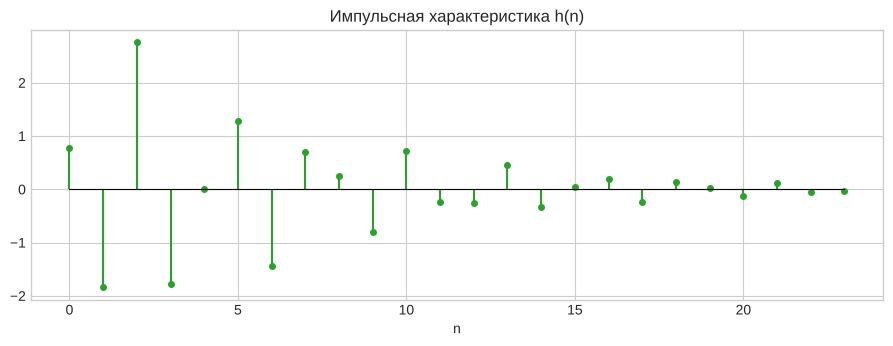

In [4]:
u0 = np.zeros(N1)
u0[0] = 1
h = raz_ur(ch, zn, u0)

print('совпадает с lfilter:', np.allclose(h, lfilter(ch, zn, u0)))

fig, ax = plt.subplots(figsize=(11, 3.5))
ris(ax, np.arange(N1), h, 'Импульсная характеристика h(n)', c='C2')
plt.show()

Импульсную характеристику (ИХ) получаем, подавая на вход $u_0(n)$. При нулевых начальных условиях

$$h(n)=\sum_{i=0}^{2}b_i\,r^{n-i}\frac{\sin((n-i+1)\theta)}{\sin\theta}\,u_1(n-i),$$

где $r=\sqrt{a_2}=0.8509$, $\cos\theta=-a_1/(2r)$, $\theta=0.7306\pi$. Подставив числа:

$$h(n)=0.8509^n\left[1.0416\sin((n+1)\theta)\,u_1(n)-1.5074\sin(n\theta)\,u_1(n-1)+2.3018\sin((n-1)\theta)\,u_1(n-2)\right].$$

Ту же ИХ при $n\geq 0$ можно получить через разложение $H(z)$ на простые дроби.

$$h(n)=A_0u_0(n)+A_1p_1^n+A_2p_2^n.$$

In [5]:
A, p, A0 = residuez(ch, zn)
r = abs(p[0])
teta = np.angle(p[0])
nn = np.arange(N1)

h1 = np.zeros(N1)
for i in range(3):
    m = nn - i
    h1 += ch[i] * (m >= 0) * r**m * np.sin((m + 1) * teta) / np.sin(teta)

h2 = (A[0] * p[0]**nn + A[1] * p[1]**nn).real
h2[0] += A0[0]

print('r =', round(r, 4), ' teta =', round(teta / np.pi, 4), 'pi')
print('A0 =', np.round(A0, 4), ' A =', np.round(A, 4))
print('через синусы:', np.allclose(h1, h))
print('через дроби:', np.allclose(h2, h))

r = 0.8509  teta = 0.7306 pi
A0 = [1.7238]  A = [-0.4719+1.8616j -0.4719-1.8616j]
через синусы: True
через дроби: True


$A_0=1.7238$, $A_{1,2}=-0.4719\pm j1.8616$, $p_{1,2}=0.8509e^{\pm j0.7306\pi}$.

ИХ рекурсивного звена бесконечная: множитель $0.8509^n$ уменьшается, но нулем не становится. На графике показаны первые 24 отсчета.

### 1.2. Реакция через свертку

совпадает с np.convolve: True
длина полной свертки: 57


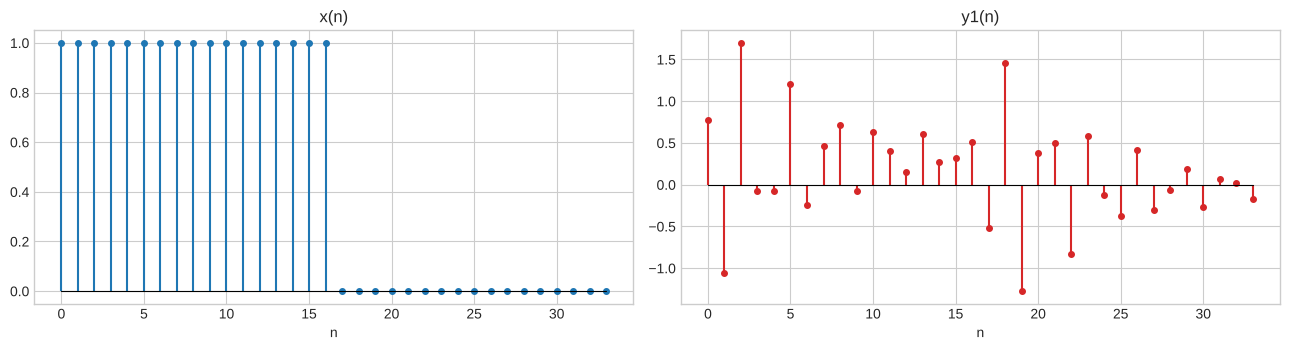

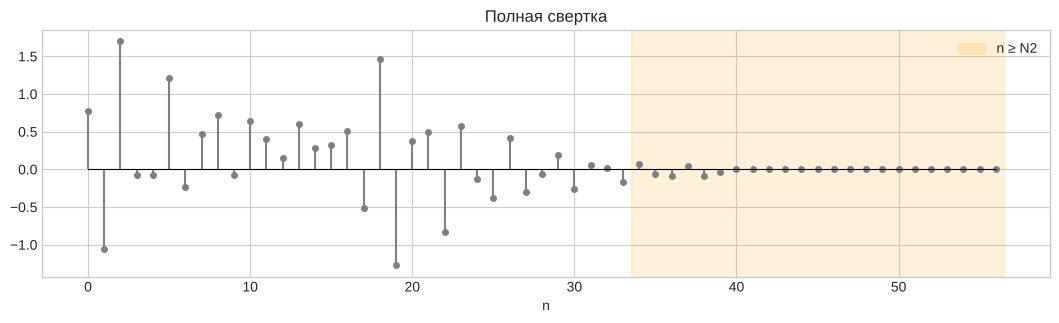

In [6]:
x = np.zeros(N2)
x[:N2 // 2] = 1
n2 = np.arange(N2)

y1 = svertka(x, h, N2)
y1_vse = np.convolve(x, h)
print('совпадает с np.convolve:', np.allclose(y1, y1_vse[:N2]))
print('длина полной свертки:', len(y1_vse))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ris(ax[0], n2, x, 'x(n)')
ris(ax[1], n2, y1, 'y1(n)', c='C3')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 3.2))
ris(ax, np.arange(len(y1_vse)), y1_vse, 'Полная свертка', c='C7')
ax.axvspan(N2 - 0.5, len(y1_vse) - 0.5, color='orange', alpha=0.15, label='n ≥ N2')
ax.legend(loc='upper right')
plt.show()

Длина импульса 17 отсчетов ($n=0\ldots16$).

Длина свертки $N_1+N_2-1=57$. На графике последний ненулевой отсчет при $n=39$, потом идут нули, так как вторая половина воздействия нулевая.

Свертку ограничивают длиной воздействия $N_2$, чтобы сравнить ее с реакцией по разностному уравнению, которая тоже имеет длину $N_2$.

### 1.3. Реакция через разностное уравнение

$$y(n)=0.78x(n)-0.9605x(n-1)+1.248x(n-2)-1.1278y(n-1)-0.724y(n-2)$$

совпадает с lfilter: True


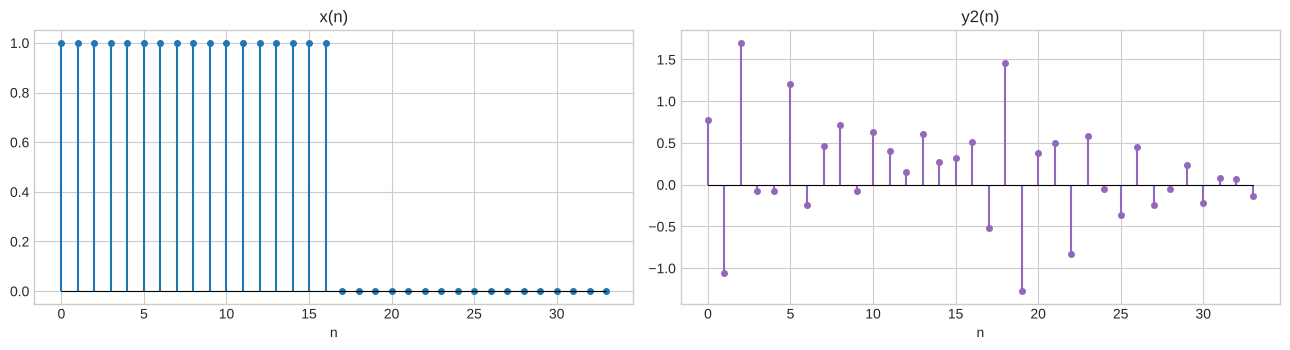

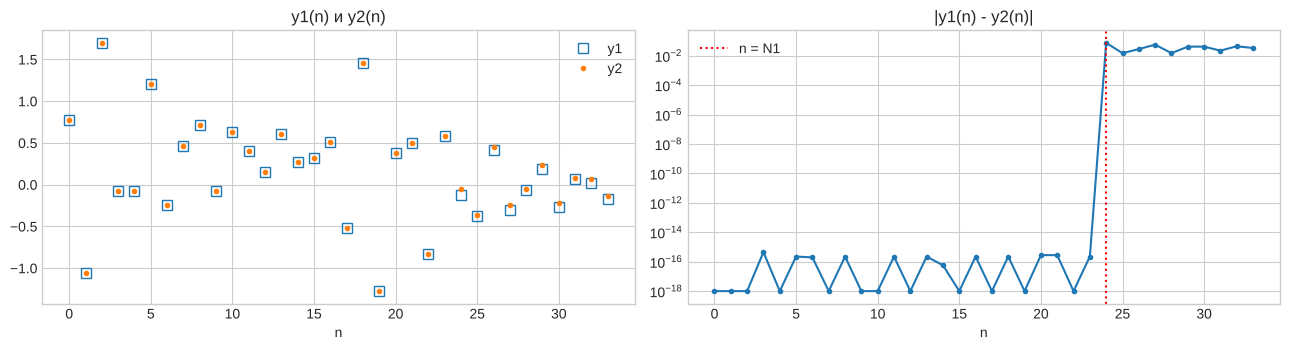

In [7]:
y2 = raz_ur(ch, zn, x)
print('совпадает с lfilter:', np.allclose(y2, lfilter(ch, zn, x)))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ris(ax[0], n2, x, 'x(n)')
ris(ax[1], n2, y2, 'y2(n)', c='C4')
plt.tight_layout()
plt.show()

raz = abs(y1 - y2)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].plot(n2, y1, 's', mfc='none', ms=7, label='y1')
ax[0].plot(n2, y2, '.', ms=6, label='y2')
ax[0].set_title('y1(n) и y2(n)')
ax[0].set_xlabel('n')
ax[0].legend()
ax[1].semilogy(n2, raz + 1e-18, 'o-', ms=3)
ax[1].axvline(N1, color='r', ls=':', label='n = N1')
ax[1].set_title('|y1(n) - y2(n)|')
ax[1].set_xlabel('n')
ax[1].legend()
plt.tight_layout()
plt.show()

У воздействия и реакции одинаковая длина, 34 отсчета.

$y_1$ и $y_2$ совпадают до $n=23$. С $n=24$ появляется разница до 0.075, потому что в свертке использовалась ИХ только из 24 отсчетов.

### 1.4. Нули и полюсы

In [8]:
nuli = np.roots(ch)
polusa = np.roots(zn)

tab = []
for q in nuli:
    tab.append(['нуль', q.real, q.imag, abs(q), np.angle(q) / np.pi])
for q in polusa:
    tab.append(['полюс', q.real, q.imag, abs(q), np.angle(q) / np.pi])
pd.DataFrame(tab, columns=['', 'Re', 'Im', 'модуль', 'аргумент / pi']).round(4)

,,Re,Im,модуль,аргумент / pi
0,нуль,0.6157,1.1049,1.2649,0.3382
1,нуль,0.6157,-1.1049,1.2649,-0.3382
2,полюс,-0.5639,0.6372,0.8509,0.7306
3,полюс,-0.5639,-0.6372,0.8509,-0.7306


$z_{1,2}=0.6157\pm j1.1049=1.2649e^{\pm j0.3382\pi}$

$p_{1,2}=-0.5639\pm j0.6372=0.8509e^{\pm j0.7306\pi}$

Модуль равен $\sqrt{\mathrm{Re}^2+\mathrm{Im}^2}$, аргумент $\operatorname{atan2}(\mathrm{Im},\mathrm{Re})$. Обратный переход: $\mathrm{Re}=r\cos\varphi$, $\mathrm{Im}=r\sin\varphi$.

$$H(z)=0.78\cdot\frac{(1-1.2649e^{j0.3382\pi}z^{-1})(1-1.2649e^{-j0.3382\pi}z^{-1})}{(1-0.8509e^{j0.7306\pi}z^{-1})(1-0.8509e^{-j0.7306\pi}z^{-1})}$$

### 1.5. Карта нулей и полюсов

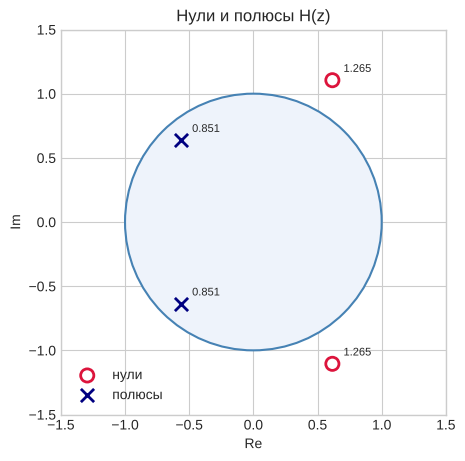

In [9]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.add_patch(plt.Circle((0, 0), 1, fill=True, fc='#eef3fb', ec='steelblue', lw=1.5))
ax.scatter(nuli.real, nuli.imag, s=90, facecolors='none', edgecolors='crimson', linewidths=2, label='нули')
ax.scatter(polusa.real, polusa.imag, s=90, marker='x', c='navy', linewidths=2, label='полюсы')
for q in list(nuli) + list(polusa):
    ax.annotate(str(round(abs(q), 3)), (q.real, q.imag), textcoords='offset points', xytext=(8, 6), fontsize=8)
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect('equal')
ax.set_xlabel('Re')
ax.set_ylabel('Im')
ax.set_title('Нули и полюсы H(z)')
ax.legend(loc='lower left')
plt.show()

Полюсы лежат внутри единичного круга ($|p|=0.851$), значит звено устойчивое. Нули снаружи ($|z|=1.265$), на устойчивость они не влияют.

Положение точек на карте совпадает со значениями из п. 1.4.

### 1.6. АЧХ и ФЧХ, нормированная частота

$H(e^{j\hat\omega})$ считаю подстановкой $z=e^{j\hat\omega}$.

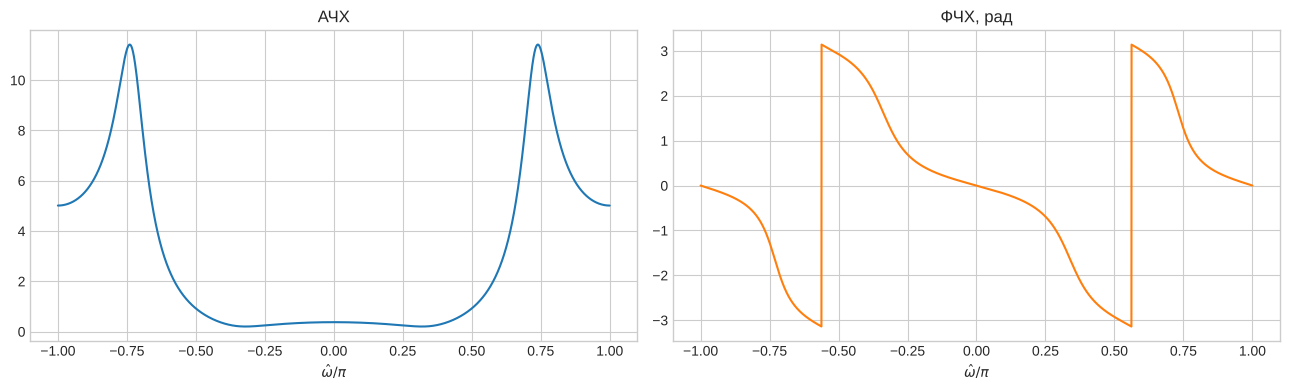

|H| при 0: 0.374  при pi: 5.013
максимум 11.42 при 0.74 pi
минимум 0.201 при 0.32 pi


In [10]:
w = np.linspace(-np.pi, np.pi, 4001)
ez = np.exp(1j * w)
H = np.polyval(ch, ez) / np.polyval(zn, ez)
modH = abs(H)
argH = np.angle(H)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(w / np.pi, modH, color='C0')
ax[0].set_title('АЧХ')
ax[0].set_xlabel(r'$\hat\omega/\pi$')
ax[1].plot(w / np.pi, argH, color='C1')
ax[1].set_title('ФЧХ, рад')
ax[1].set_xlabel(r'$\hat\omega/\pi$')
plt.tight_layout()
plt.show()

w0 = w[w >= 0]
H0 = modH[w >= 0]
print('|H| при 0:', round(H0[0], 3), ' при pi:', round(H0[-1], 3))
print('максимум', round(H0.max(), 2), 'при', round(w0[H0.argmax()] / np.pi, 3), 'pi')
print('минимум', round(H0.min(), 3), 'при', round(w0[H0.argmin()] / np.pi, 3), 'pi')

Основная полоса частот $0\leq\hat\omega\leq\pi$. На графике взят интервал от $-\pi$ до $\pi$: видно, что АЧХ четная, а ФЧХ нечетная.

Максимум АЧХ (11.4 при $0.740\pi$) находится рядом с аргументом полюса $0.731\pi$. Полюс близко к окружности, поэтому пик высокий. Минимум (0.20 при $0.320\pi$) рядом с аргументом нуля $0.338\pi$, но так как нуль лежит вне круга, АЧХ до нуля не опускается.

Скачок ФЧХ на $\pi$ бывает при нулевом значении АЧХ, а здесь АЧХ нигде не равна нулю. Разрыв около $0.56\pi$ равен $2\pi$, это фаза перешла через $-\pi$.

$|H(0)|=0.37$, $|H(\pi)|=5.0$, то есть звено подавляет низкие частоты. Прямоугольный импульс в основном низкочастотный, поэтому на плоской части $y_2(n)$ держится около 0.4, а на фронтах ($n=2$ и $n=18$) видны всплески.

### 1.7. АЧХ и ФЧХ в герцах

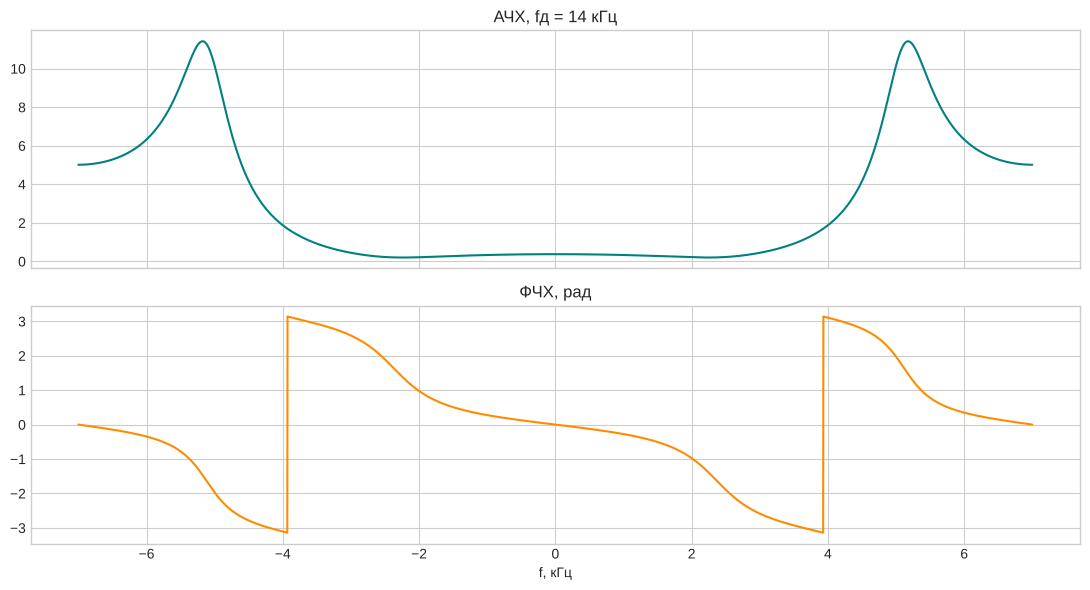

максимум АЧХ при f = 5176 Гц


In [11]:
fg = w * fd / (2 * np.pi)

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(fg / 1000, modH, color='teal')
ax[0].set_title('АЧХ, fд = 14 кГц')
ax[1].plot(fg / 1000, argH, color='darkorange')
ax[1].set_title('ФЧХ, рад')
ax[1].set_xlabel('f, кГц')
plt.tight_layout()
plt.show()
print('максимум АЧХ при f =', round(w0[H0.argmax()] * fd / (2 * np.pi)), 'Гц')

Основная полоса $0\leq f\leq f_д/2=7$ кГц.

$f=\hat\omega f_д/(2\pi)$: $\hat\omega=\pi$ соответствует 7 кГц, максимум при $0.740\pi$ соответствует 5176 Гц.

## Часть 2

In [12]:
N = 64
fd2 = 2000 * (Nv % 5 + 1)
T = 1 / fd2
A1 = 1 + 0.01 * Nv
A2 = 2 * A1
f1 = fd2 / 8
f2 = 1.5 * f1
print('N =', N, '; fд =', fd2, 'Гц; T =', T * 1e6, 'мкс')
print('A1 =', round(A1, 2), ', A2 =', round(A2, 2), '; f1 =', f1, ', f2 =', f2)

N = 64 ; fд = 10000 Гц; T = 100.0 мкс
A1 = 1.14 , A2 = 2.28 ; f1 = 1250.0 , f2 = 1875.0


### 2.1. Последовательность x(n)

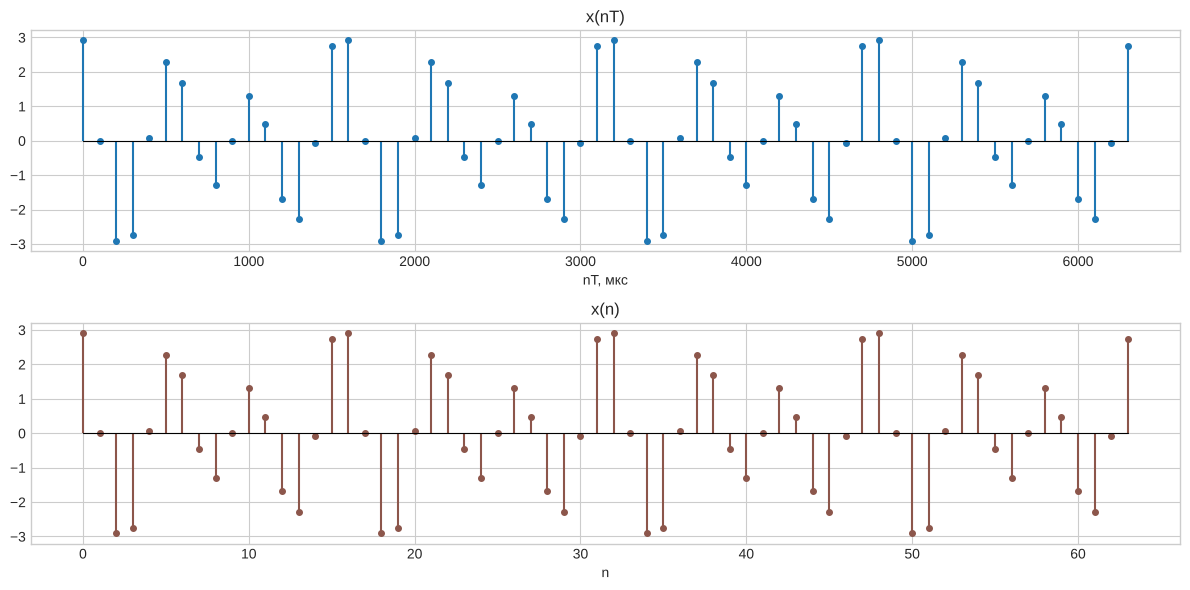

In [13]:
n = np.arange(N)
x = A1 * np.cos(2 * np.pi * f1 * n * T + np.pi / 4) + A2 * np.cos(2 * np.pi * f2 * n * T + np.pi / 8)

fig, ax = plt.subplots(2, 1, figsize=(12, 6))
ris(ax[0], n * T * 1e6, x, 'x(nT)', xl='nT, мкс', c='C0')
ris(ax[1], n, x, 'x(n)', xl='n', c='C5')
plt.tight_layout()
plt.show()

### 2.2. ОДПФ

ДПФ считаю через матрицу $W_{kn}=e^{-j2\pi kn/N}$.

совпадает с np.fft.fft: True


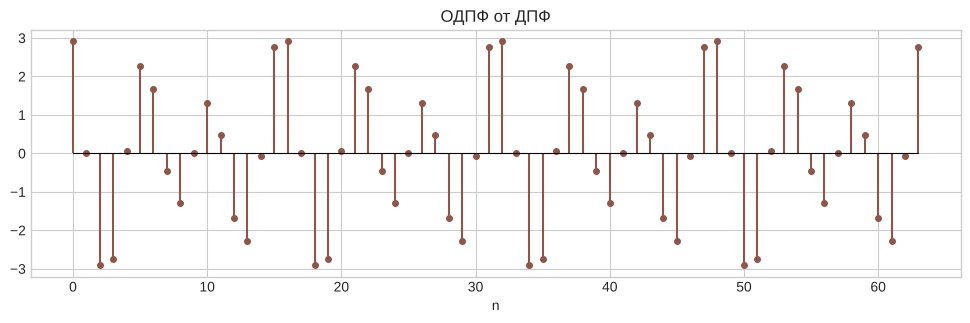

совпадает с x(n): True


In [14]:
W = np.exp(-2j * np.pi * np.outer(n, n) / N)
X = W @ x
print('совпадает с np.fft.fft:', np.allclose(X, np.fft.fft(x)))

x_o = ((np.conj(W) @ X) / N).real
fig, ax = plt.subplots(figsize=(12, 3.2))
ris(ax, n, x_o, 'ОДПФ от ДПФ', c='C5')
plt.show()
print('совпадает с x(n):', np.allclose(x_o, x))

После ОДПФ получилась исходная последовательность.

### 2.3. Амплитудный и фазовый спектры

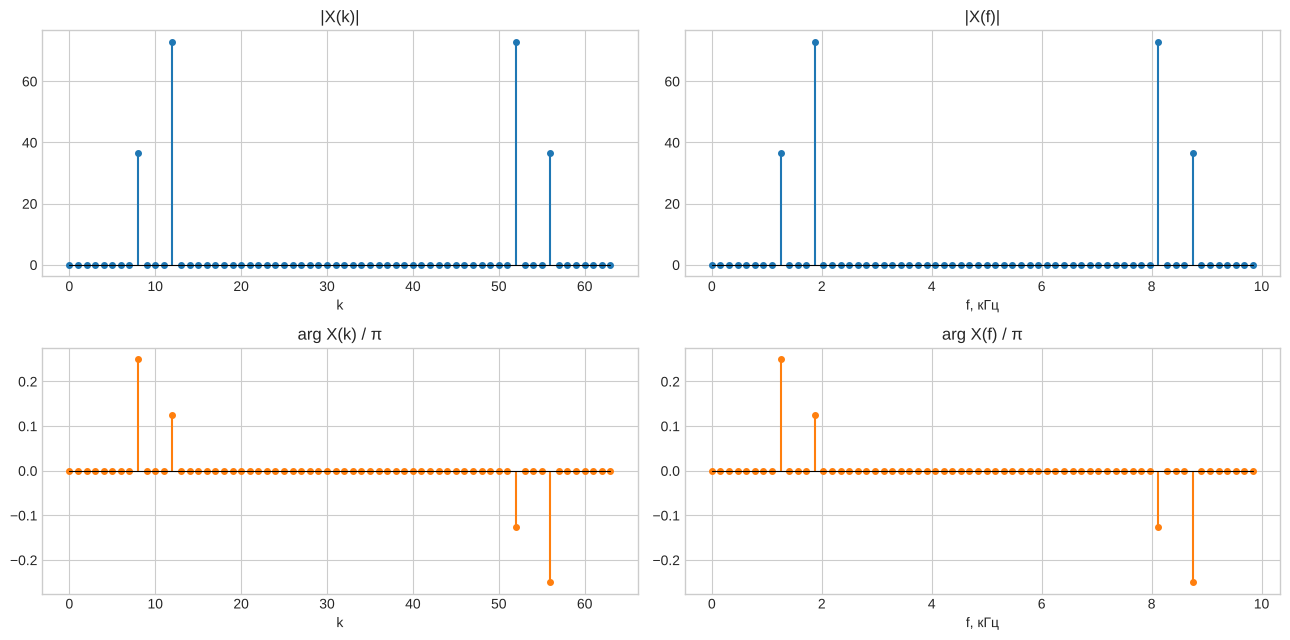

,k,"f, Гц",|X(k)|,arg / pi
0,8,1250.0,36.48,0.250
1,12,1875.0,72.96,0.125
2,52,8125.0,72.96,-0.125
3,56,8750.0,36.48,-0.250


In [15]:
k = np.arange(N)
df = fd2 / N
modX = abs(X)
argX = np.angle(X)
argX[modX < 1e-9] = 0

fig, ax = plt.subplots(2, 2, figsize=(13, 6.5))
ris(ax[0, 0], k, modX, '|X(k)|', xl='k', c='C0')
ris(ax[1, 0], k, argX / np.pi, 'arg X(k) / π', xl='k', c='C1')
ris(ax[0, 1], k * df / 1000, modX, '|X(f)|', xl='f, кГц', c='C0')
ris(ax[1, 1], k * df / 1000, argX / np.pi, 'arg X(f) / π', xl='f, кГц', c='C1')
plt.tight_layout()
plt.show()

ind = modX > 1e-9
pd.DataFrame({'k': k[ind], 'f, Гц': k[ind] * df, '|X(k)|': modX[ind], 'arg / pi': argX[ind] / np.pi}).round(3)

Дискретное время $nT$ измеряется в секундах (шаг 100 мкс), нормированное время $n=nT/T$ равно номеру отсчета.

Частота в герцах $f=k\,f_д/N$, шаг $156.25$ Гц.

В спектре две пары линий: $k=8$ и $k=12$ (1250 и 1875 Гц) и симметричные им $k=56$ и $k=52$. Высота 36.48 и 72.96, это $NA_1/2$ и $NA_2/2$. Фаза на $k=8$ равна $\pi/4$, на $k=12$ равна $\pi/8$, то есть начальным фазам гармоник. На $k=56$ и $k=52$ фаза с противоположным знаком. Амплитудный спектр четный, фазовый нечетный.

### 2.4. ДПФ конечной последовательности

Серая линия соединяет 4096 отсчетов спектра конечной последовательности. Чтобы получить эти отсчеты, последовательность дополняют нулями до 4096 точек и вычисляют ДПФ.

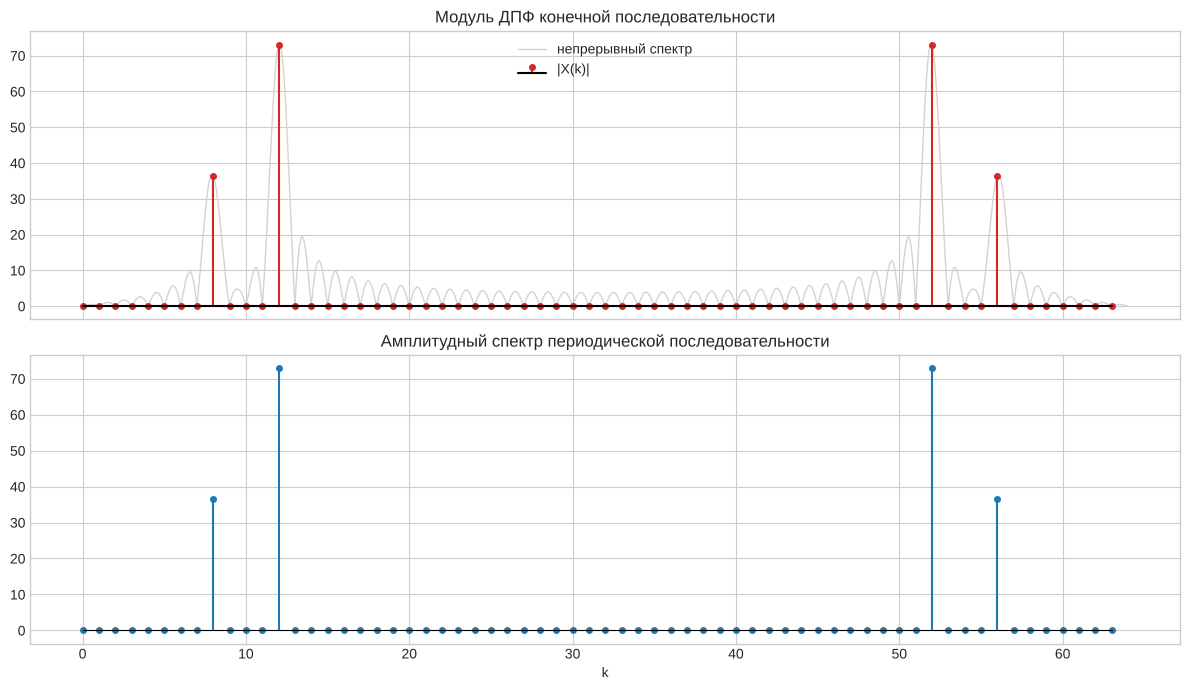

In [16]:
Xk = np.fft.fft(x)
Xn = np.fft.fft(x, 4096)

fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(np.arange(4096) * N / 4096, abs(Xn), color='lightgray', lw=1, label='непрерывный спектр')
m, s, bl = ax[0].stem(k, abs(Xk), linefmt='C3', markerfmt='C3o', basefmt='k-', label='|X(k)|')
plt.setp(m, markersize=4)
ax[0].set_title('Модуль ДПФ конечной последовательности')
ax[0].legend(loc='upper center')
ris(ax[1], k, modX, 'Амплитудный спектр периодической последовательности', xl='k', c='C0')
plt.tight_layout()
plt.show()

ДПФ конечной последовательности совпадает с ДПФ одного периода, потому что в обоих расчетах используются одни и те же $N=64$ отсчета сигнала.

Спектр конечной последовательности непрерывен, а ДПФ дает его значения в точках $\hat\omega=2\pi k/N$. На этой сетке ненулевые значения получились при $k=8, 12, 52, 56$. Ближайшие максимумы непрерывного спектра немного смещены относительно этих точек.

### 2.5. Восстановление аналогового сигнала

In [17]:
Xa = np.concatenate((X[N // 2:], X[:N // 2]))     # k от -N/2 до N/2-1
kn = np.arange(-N // 2, N // 2)

t = np.arange(0, (N - 1) * T + 1e-12, 0.25 * T)
xt = 0
for i in range(N):
    xt = xt + Xa[i] * np.exp(1j * 2 * np.pi * kn[i] * t / (N * T))
xt = (xt / N).real

x_isx = A1 * np.cos(2 * np.pi * f1 * t + np.pi / 4) + A2 * np.cos(2 * np.pi * f2 * t + np.pi / 8)

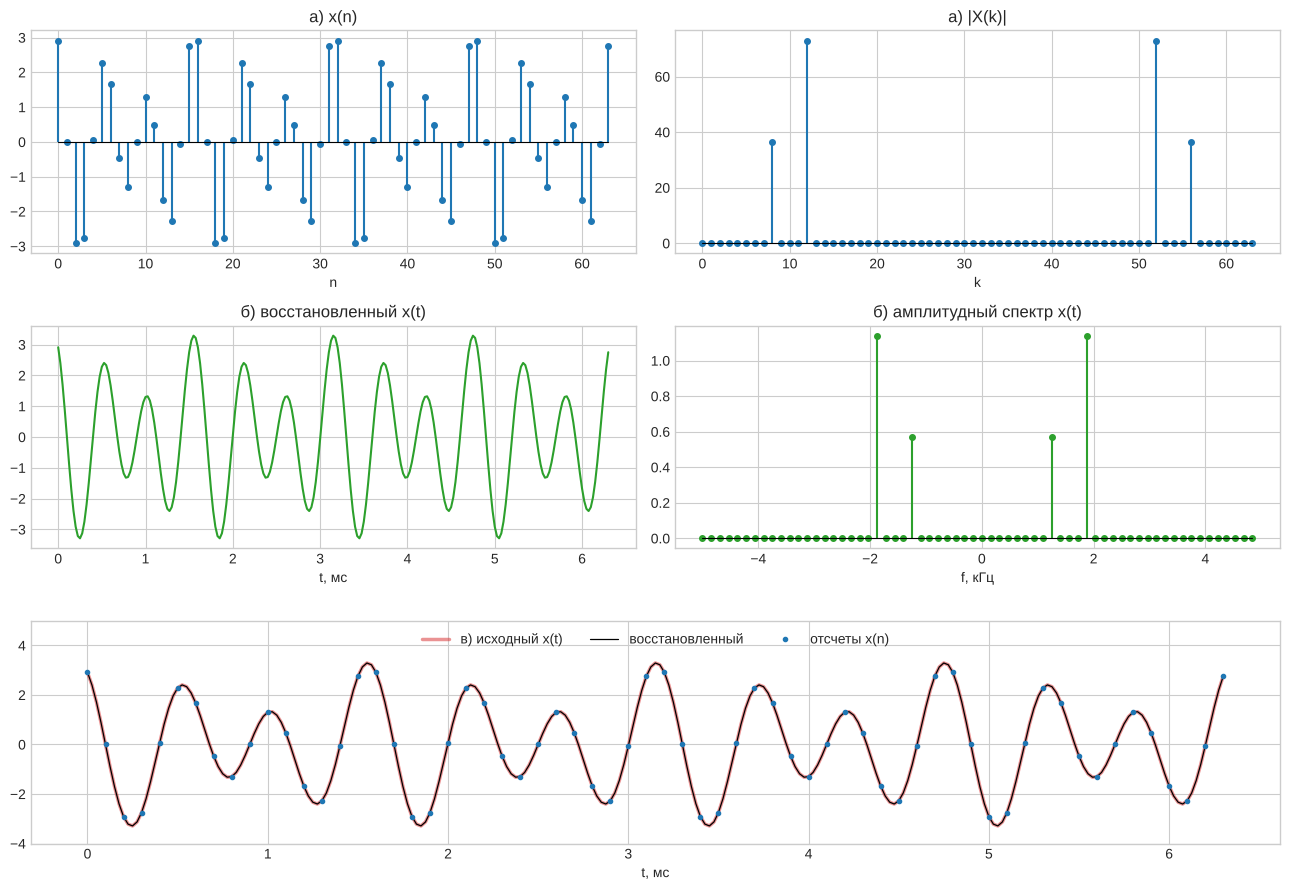

совпадает с исходным: True


In [18]:
fa = kn / (N * T)

fig = plt.figure(figsize=(13, 9))
gs = fig.add_gridspec(3, 2)
ris(fig.add_subplot(gs[0, 0]), n, x, 'а) x(n)')
ris(fig.add_subplot(gs[0, 1]), k, modX, 'а) |X(k)|', xl='k')
ax = fig.add_subplot(gs[1, 0])
ax.plot(t * 1000, xt, color='C2')
ax.set_title('б) восстановленный x(t)')
ax.set_xlabel('t, мс')
ris(fig.add_subplot(gs[1, 1]), fa / 1000, abs(Xa) / N, 'б) амплитудный спектр x(t)', xl='f, кГц', c='C2')
ax = fig.add_subplot(gs[2, :])
ax.plot(t * 1000, x_isx, color='C3', lw=2.5, alpha=0.5, label='в) исходный x(t)')
ax.plot(t * 1000, xt, 'k', lw=0.9, label='восстановленный')
ax.plot(n * T * 1000, x, 'o', color='C0', ms=3, label='отсчеты x(n)')
ax.set_xlabel('t, мс')
ax.set_ylim(-4, 5)
ax.legend(loc='upper center', ncol=3)
plt.tight_layout()
plt.show()

print('совпадает с исходным:', np.allclose(xt, x_isx))

### 2.6. Выводы по п. 2.5

Если отсчеты ДПФ с номерами от $N/2$ до $N-1$ перенести в отрицательные частоты и поделить на $N$, получается амплитудный спектр аналогового сигнала: линии на $\pm1.25$ и $\pm1.875$ кГц высотой $A_1/2=0.57$ и $A_2/2=1.14$. Это выполняется, потому что обе частоты меньше $f_д/2=5$ кГц и на длине $N$ укладывается целое число периодов.

Восстановленный сигнал совпадает с исходным, отсчеты $x(n)$ лежат на кривой.

### 2.7. Равенство Парсеваля

In [19]:
S1 = np.sum(x**2)
S2 = np.sum(abs(X)**2) / N
print('sum x^2(n)         =', round(S1, 4))
print('(1/N) sum |X(k)|^2 =', round(S2, 4))

sum x^2(n)         = 207.936
(1/N) sum |X(k)|^2 = 207.936


$$\sum_{n=0}^{N-1}x^2(n)=\frac1N\sum_{k=0}^{N-1}|X(k)|^2=207.936$$

Слева энергия сигнала, посчитанная по отсчетам во времени, справа по отсчетам ДПФ. Они равны, то есть при переходе к спектру энергия сохраняется.

## Общий вывод

Звено варианта 14 устойчиво: полюсы $0.851e^{\pm j0.731\pi}$ находятся внутри единичного круга. ИХ получена тремя способами (по разностному уравнению, по формуле с синусами и через разложение на простые дроби), результаты совпали. Реакция по формуле свертки совпадает с реакцией по разностному уравнению до $n=23$, после этого расхождение доходит до 0.075 из-за того, что ИХ взята длиной всего 24 отсчета, а затухает она медленно.

АЧХ показывает, что звено подавляет низкие частоты ($|H(0)|=0.37$) и имеет резкий пик 11.4 на частоте $0.74\pi$, это около 5.2 кГц. Пик объясняется тем, что полюсы расположены близко к единичной окружности. Нули лежат вне круга, поэтому АЧХ нигде не обращается в ноль и скачков ФЧХ на $\pi$ нет.

Во второй части ДПФ суммы двух косинусов дало по две линии на каждую гармонику ($k=8, 56$ и $k=12, 52$) высотой $NA/2$, фазы линий совпали с начальными фазами. ДПФ конечной последовательности совпало с ДПФ одного периода. Восстановленный по ДПФ аналоговый сигнал совпал с исходным, а равенство Парсеваля выполнилось (207.936).